In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Sample BBO of the oral microbial communities

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, BlackBoxOptim, Distances, Printf

In [3]:
Plots.theme(:dao)

In [4]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1];

In [6]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
# first split on classification
gd1 = groupby(read_data, :classification);

For each classification, split up on the sample.

In [7]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

Index choice below specifies the index of system we are dealing with.

In [164]:
ind_choice = 13;

In [165]:
gd_classes[ind_choice];

In [166]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [167]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

3324.0

Let's choose the smallest of these systems as the initial condition.

In [168]:
argmin(sizes)

27

In [169]:
small_to_large = sortperm(sizes);

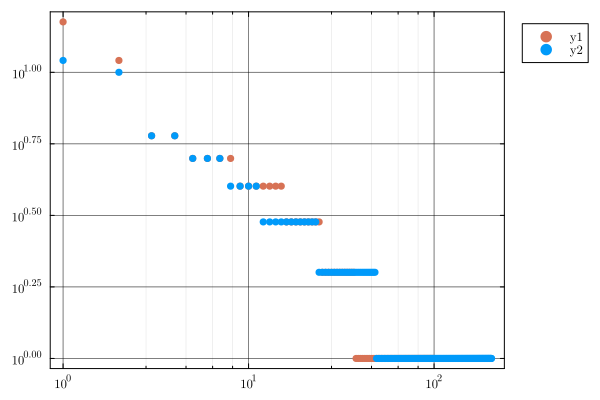

In [170]:
ic_sys = data[argmin(sizes)]
ic_sys = sort(ic_sys[!,:count],rev=true)
scatter(ic_sys, xaxis = :log, yaxis = :log)
scatter!(sort(data[small_to_large[2]][!,:count],rev=true))

In [171]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

35.57240015239553

Let's import the calibration results.

In [172]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,-4.95008,1.21516,3.43877
2,-2.33215,1.17183,1.34943
3,-4.76551,1.1602,4.13909
4,-1.99897,1.23884,0.909132
5,-4.18708,1.20094,0.932209
6,-2.3808,1.28238,0.75526
7,-4.89463,1.23444,2.88737
8,0.389472,1.26049,0.945436
9,-1.61544,1.20049,1.26212


In [173]:
calib_results[1,1]

-4.950084068016057

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [174]:
top10i = sortperm(sizes,rev=true)[1:10];
size_order = 8;
idx = top10i[size_order]

12

In [175]:
guess_sim = dsim.create_cell(calib_results[size_order,1],calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);
# guess_sim = dsim.create_cell(-10,calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);

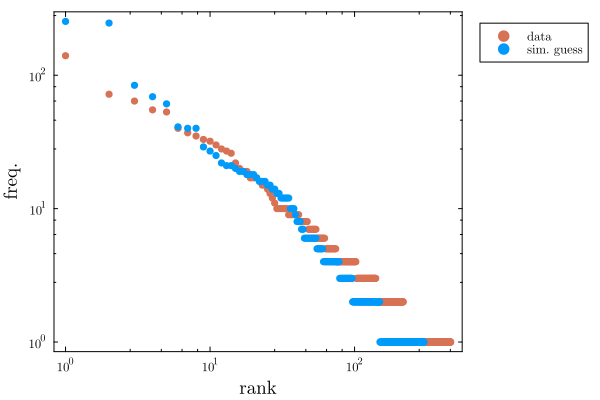

In [176]:
scatter(sort(data[idx][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data")
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

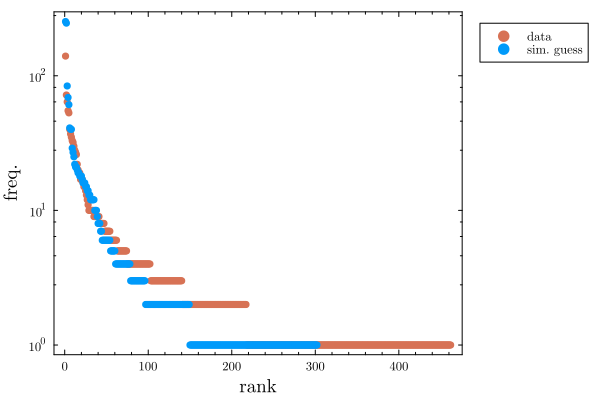

In [177]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", yaxis = :log)
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

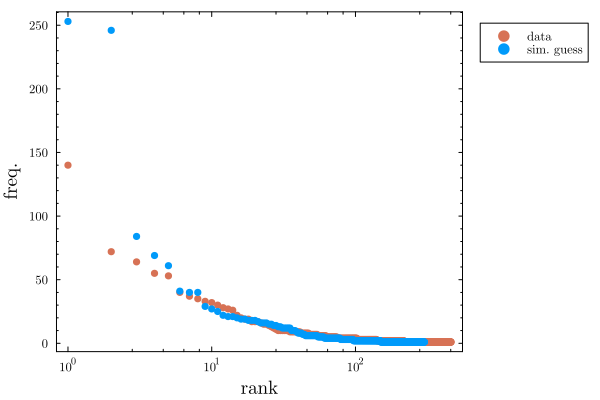

In [178]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", xaxis = :log)
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)